In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo de gráficas
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Cargar dataset (ruta relativa desde notebooks/)
df = pd.read_csv('../data/raw/online_shoppers_intention.csv')

print("Shape:", df.shape)
df.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [3]:
print("Valores nulos por columna:")
print(df.isnull().sum())

print("\nTotal de nulos:", df.isnull().sum().sum())
print("Duplicados exactos:", df.duplicated().sum())

Valores nulos por columna:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Total de nulos: 0
Duplicados exactos: 125


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [5]:
cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 
            'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())
    print(f"Proporción:\n{df[col].value_counts(normalize=True).round(3)}")


--- Month ---
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64
Proporción:
Month
May     0.273
Nov     0.243
Mar     0.155
Dec     0.140
Oct     0.045
Sep     0.036
Aug     0.035
Jul     0.035
June    0.023
Feb     0.015
Name: proportion, dtype: float64

--- OperatingSystems ---
OperatingSystems
2    6601
1    2585
3    2555
4     478
8      79
6      19
7       7
5       6
Name: count, dtype: int64
Proporción:
OperatingSystems
2    0.535
1    0.210
3    0.207
4    0.039
8    0.006
6    0.002
7    0.001
5    0.000
Name: proportion, dtype: float64

--- Browser ---
Browser
2     7961
1     2462
4      736
5      467
6      174
10     163
8      135
3      105
13      61
7       49
12      10
11       6
9        1
Name: count, dtype: int64
Proporción:
Browser
2     0.646
1     0.200
4     0.060
5     0.038
6     0.014
10    0.013
8     0.011
3     0.009
13    0.005
7     0.004

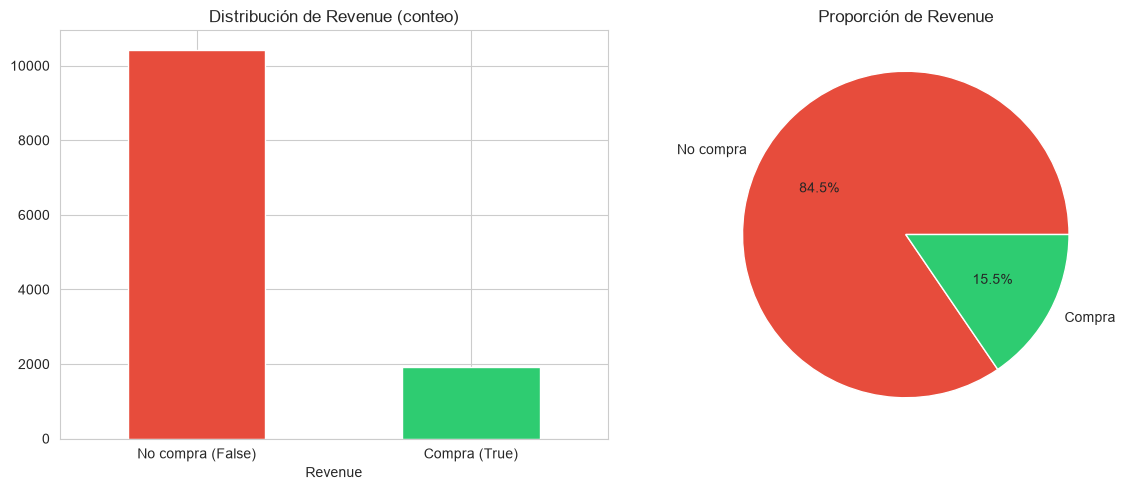

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

df['Revenue'].value_counts().plot(kind='bar', ax=ax[0], color=['#e74c3c', '#2ecc71'])
ax[0].set_title('Distribución de Revenue (conteo)')
ax[0].set_xticklabels(['No compra (False)', 'Compra (True)'], rotation=0)

df['Revenue'].value_counts(normalize=True).plot(kind='pie', ax=ax[1], 
    autopct='%1.1f%%', colors=['#e74c3c', '#2ecc71'], labels=['No compra', 'Compra'])
ax[1].set_title('Proporción de Revenue')
ax[1].set_ylabel('')

plt.tight_layout()
plt.show()

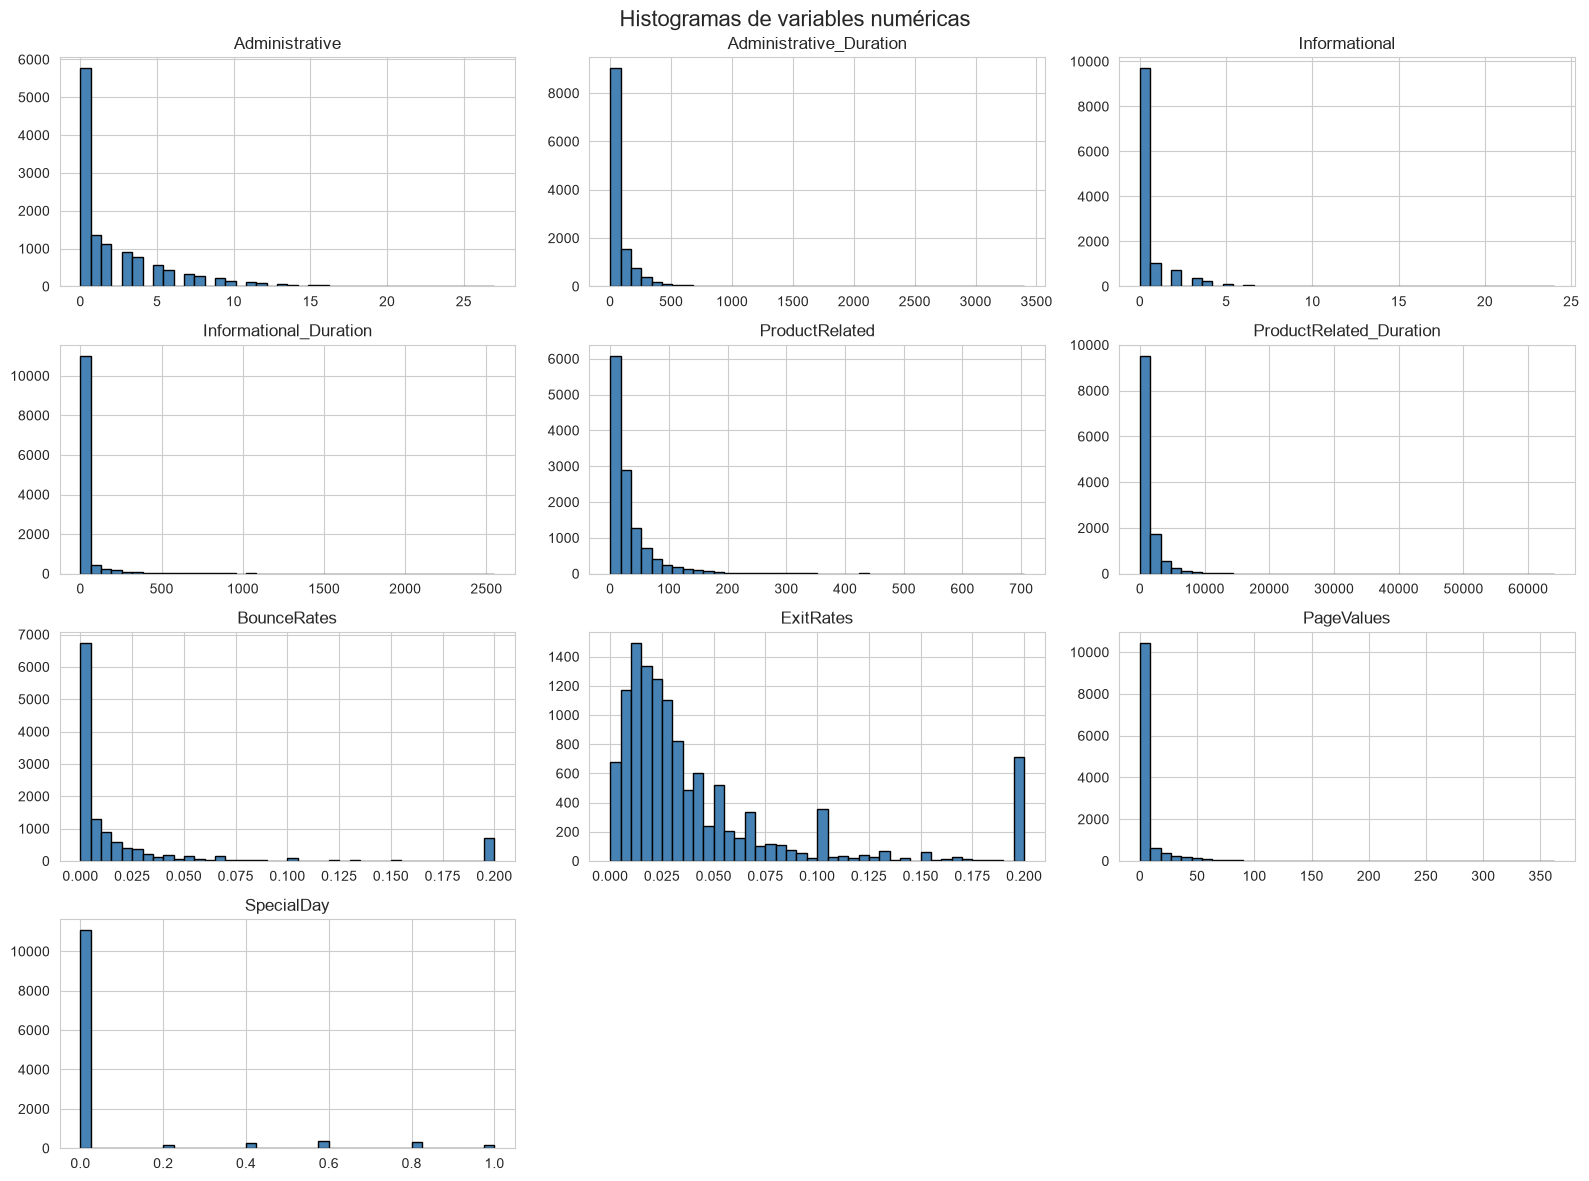

In [7]:
num_cols = ['Administrative', 'Administrative_Duration', 'Informational', 
            'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
            'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

df[num_cols].hist(bins=40, figsize=(16, 12), color='steelblue', edgecolor='black')
plt.suptitle('Histogramas de variables numéricas', fontsize=16)
plt.tight_layout()
plt.show()

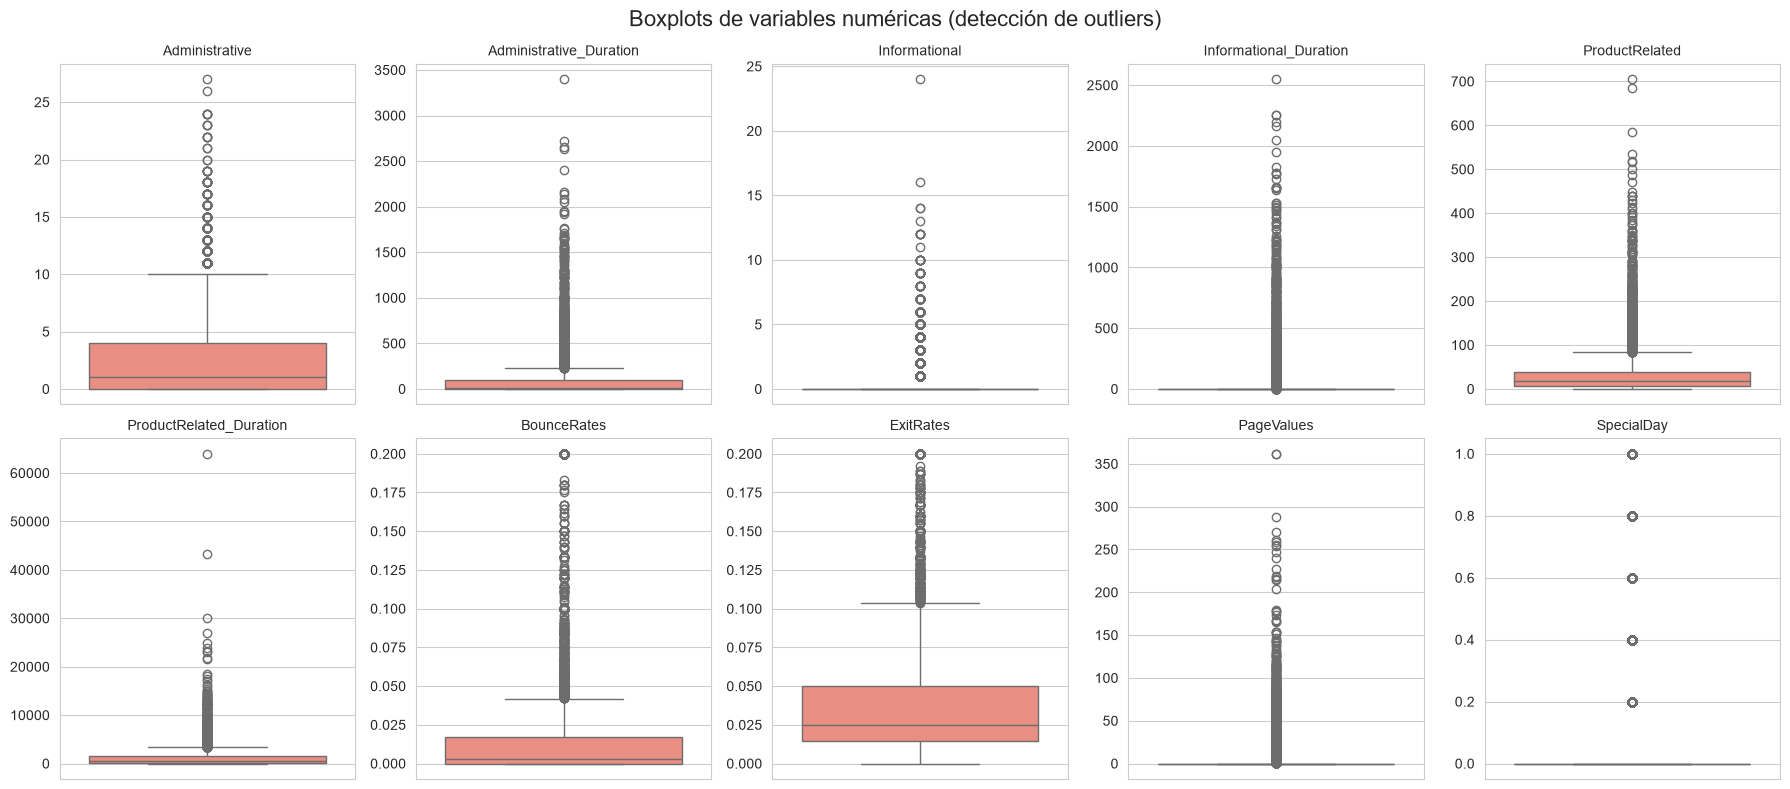

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='salmon')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel('')

plt.suptitle('Boxplots de variables numéricas (detección de outliers)', fontsize=16)
plt.tight_layout()
plt.show()

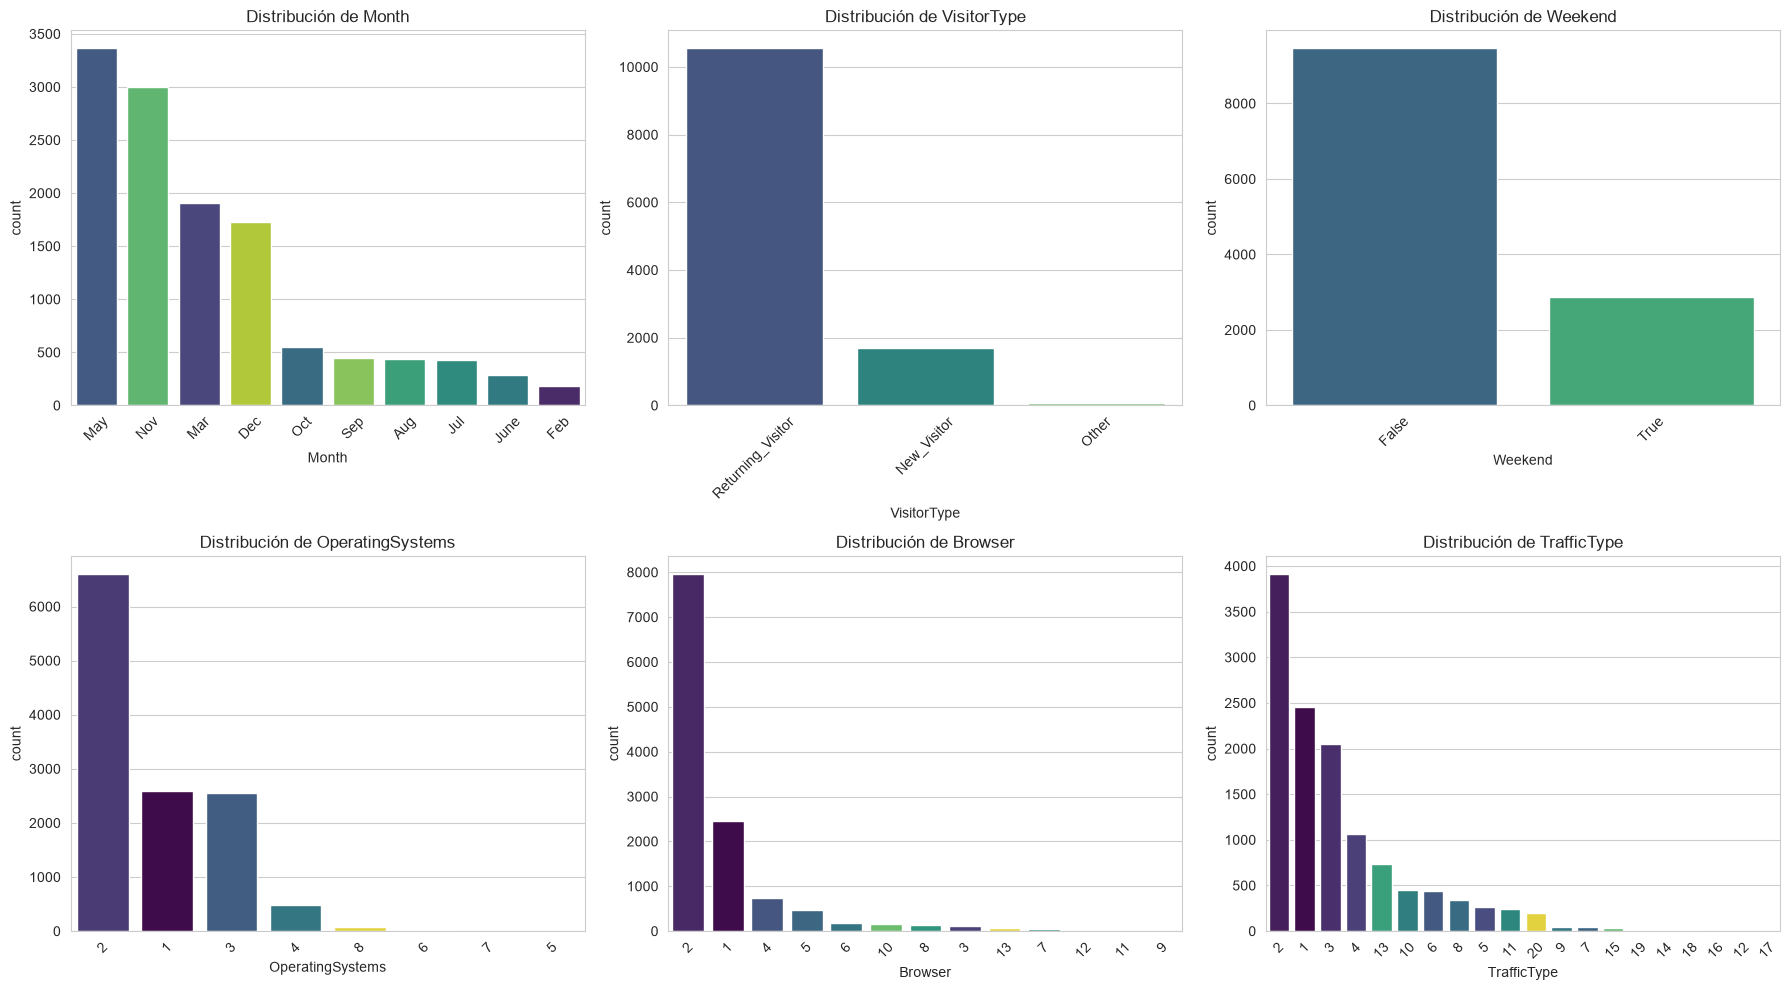

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(['Month', 'VisitorType', 'Weekend', 
                          'OperatingSystems', 'Browser', 'TrafficType']):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=axes[i], 
                  hue=col, palette='viridis', legend=False)
    axes[i].set_title(f'Distribución de {col}', fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

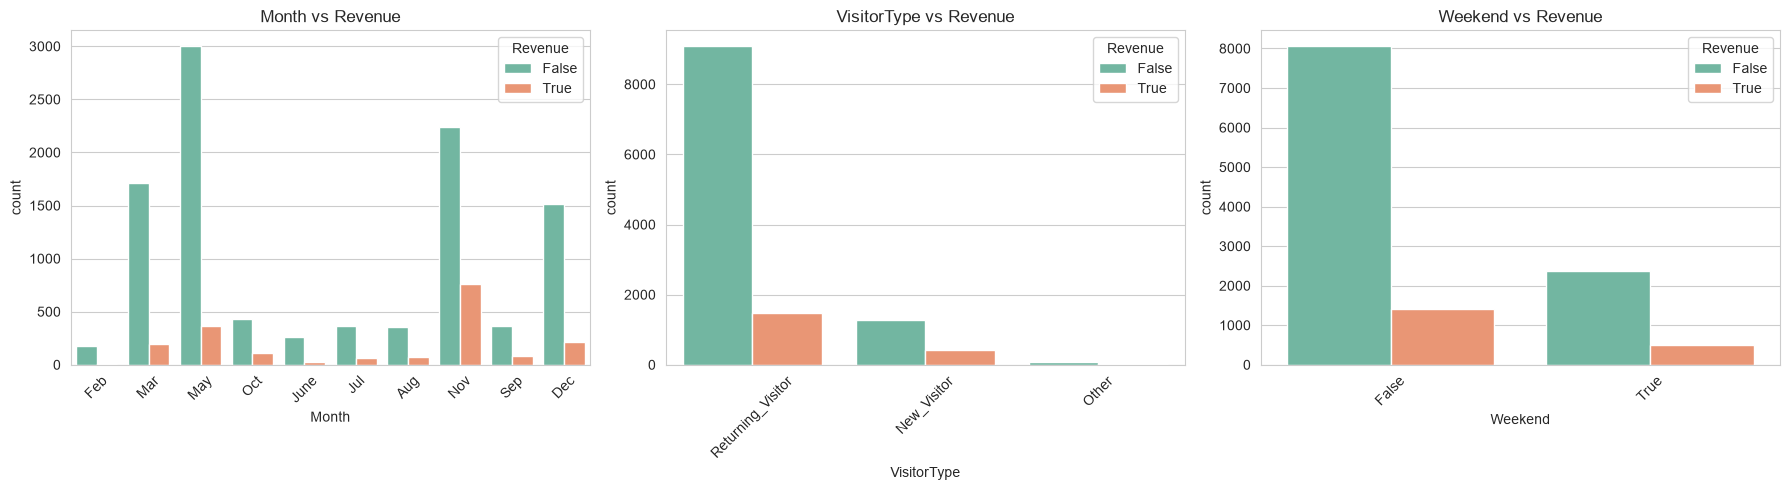

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(['Month', 'VisitorType', 'Weekend']):
    sns.countplot(data=df, x=col, hue='Revenue', ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} vs Revenue')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

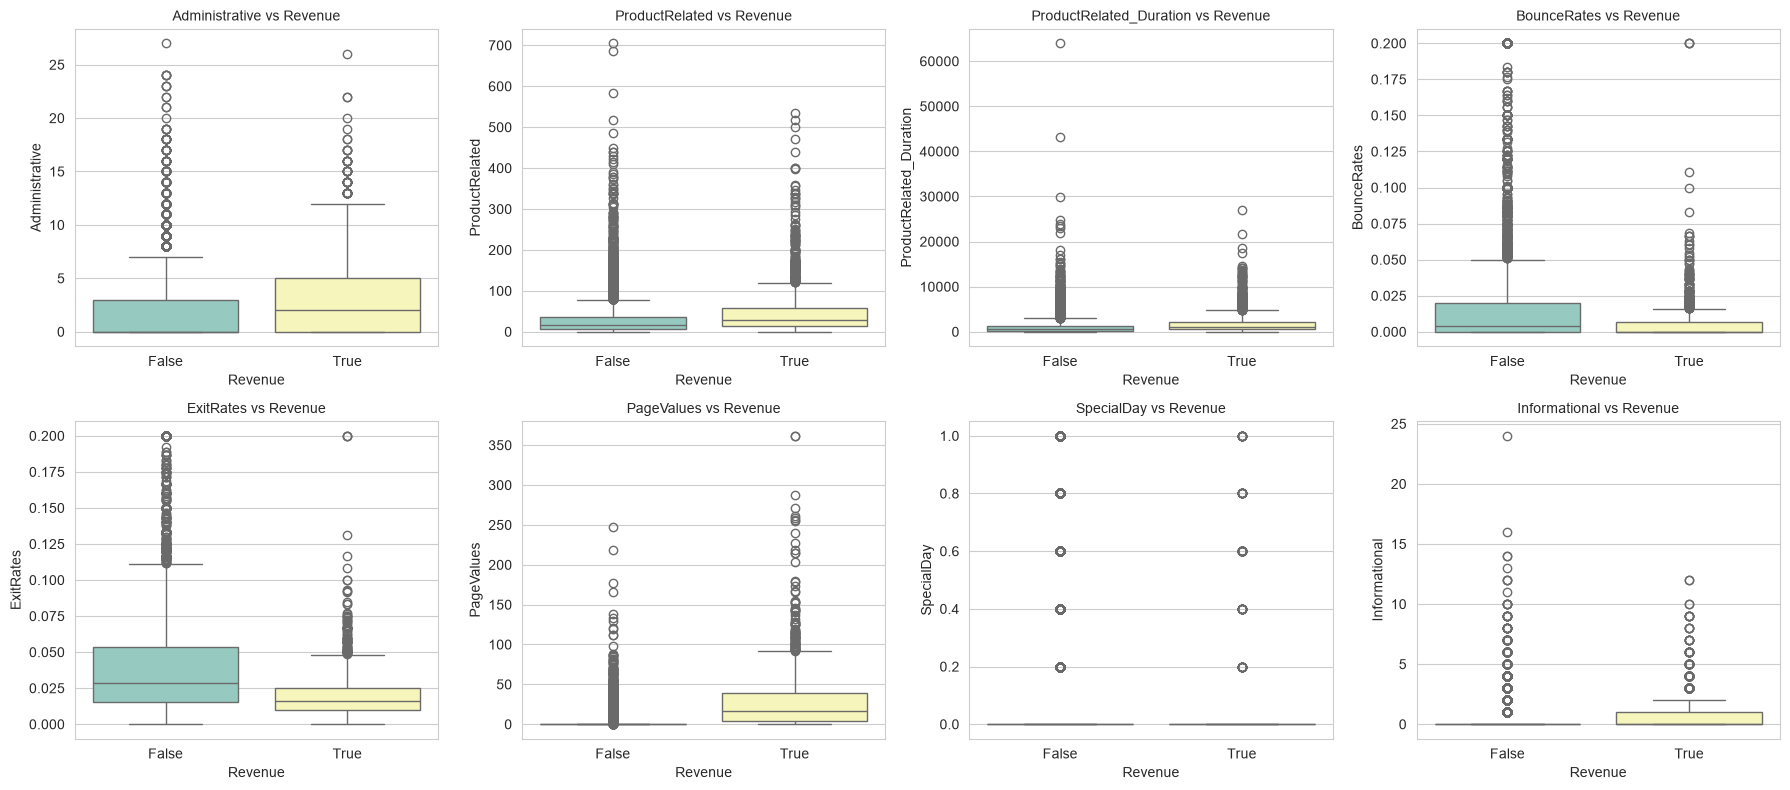

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
cols_compare = ['Administrative', 'ProductRelated', 'ProductRelated_Duration',
                'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Informational']

for i, col in enumerate(cols_compare):
    sns.boxplot(data=df, x='Revenue', y=col, ax=axes[i], 
                hue='Revenue', palette='Set3', legend=False)
    axes[i].set_title(f'{col} vs Revenue', fontsize=10)

plt.tight_layout()
plt.show()

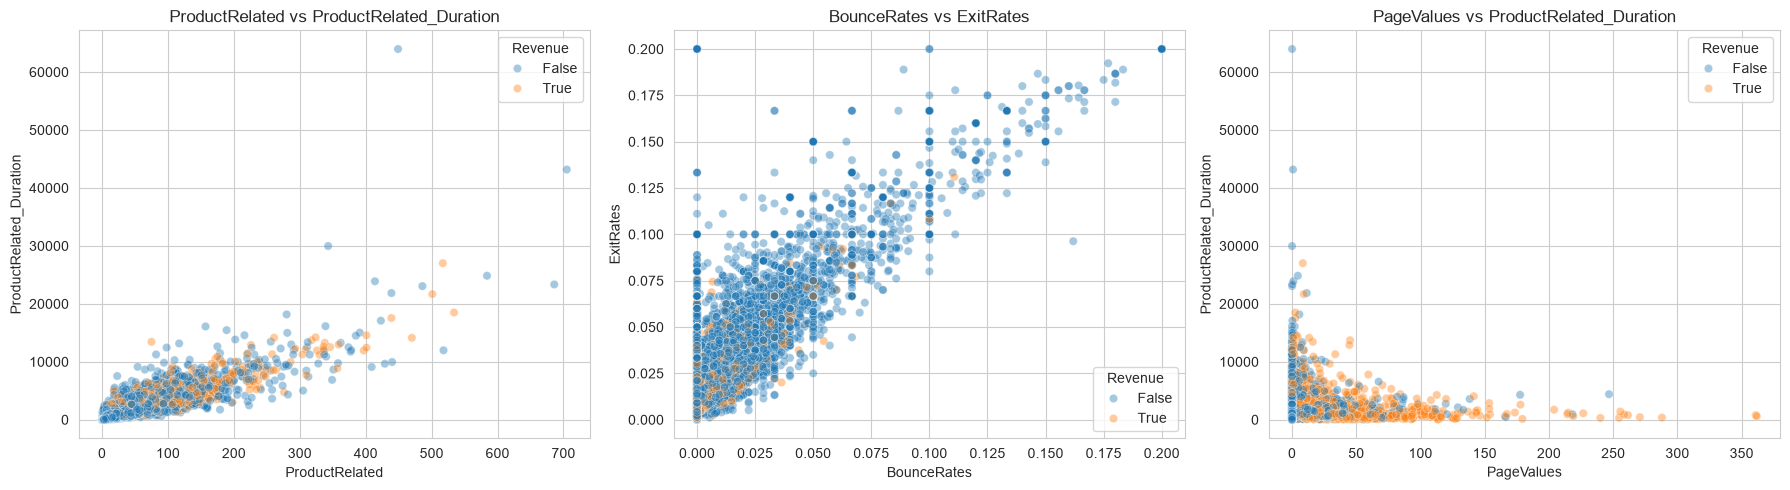

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='ProductRelated', y='ProductRelated_Duration', 
                hue='Revenue', alpha=0.4, ax=axes[0])
axes[0].set_title('ProductRelated vs ProductRelated_Duration')

sns.scatterplot(data=df, x='BounceRates', y='ExitRates', 
                hue='Revenue', alpha=0.4, ax=axes[1])
axes[1].set_title('BounceRates vs ExitRates')

sns.scatterplot(data=df, x='PageValues', y='ProductRelated_Duration', 
                hue='Revenue', alpha=0.4, ax=axes[2])
axes[2].set_title('PageValues vs ProductRelated_Duration')

plt.tight_layout()
plt.show()

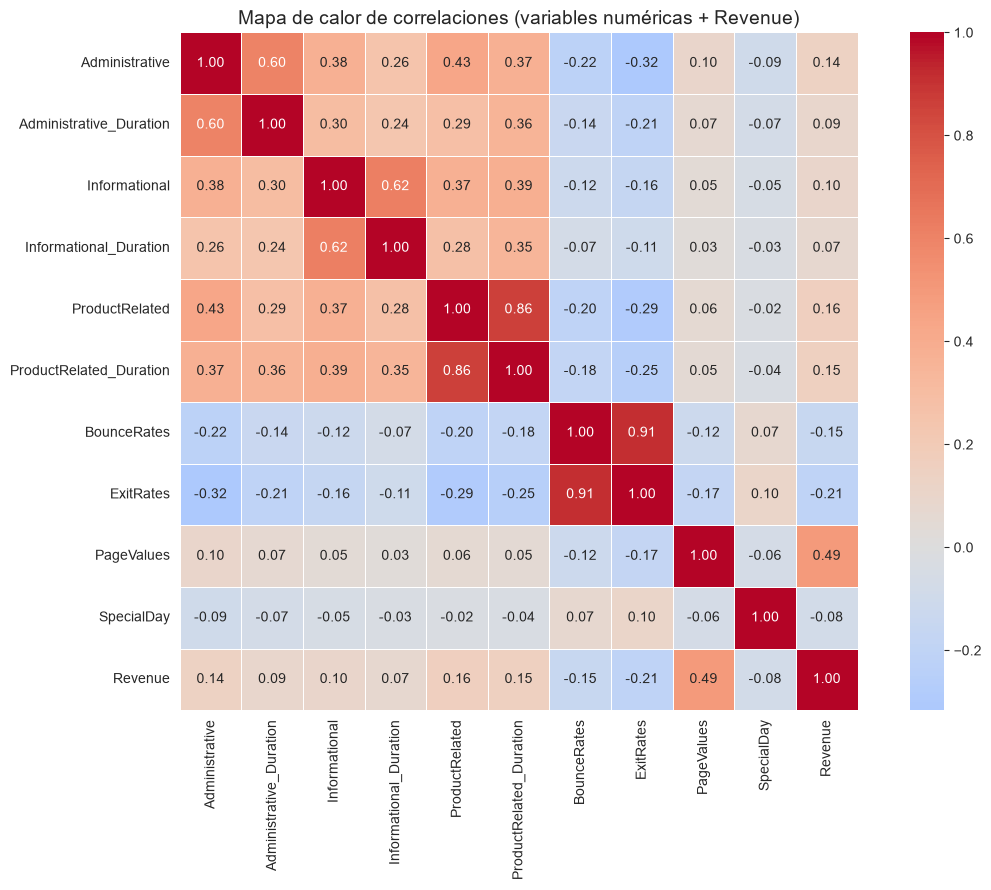

In [13]:
plt.figure(figsize=(12, 9))
corr = df[num_cols + ['Revenue']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=0.5)
plt.title('Mapa de calor de correlaciones (variables numéricas + Revenue)', fontsize=14)
plt.tight_layout()
plt.show()

## Conclusiones del EDA

1. **Dataset desbalanceado:** solo ~15.5% de sesiones terminan en compra. 
   → Usar class_weight='balanced', SMOTE y métricas como F1/recall.

2. **Predictor más fuerte:** PageValues (correlación ~0.49 con Revenue y 
   diferencia clara en boxplots). Es la variable clave para clasificación.

3. **Variables redundantes:** BounceRates y ExitRates están altamente 
   correlacionadas (~0.91). Eliminar una en el modelado.

4. **Distribuciones sesgadas:** las duraciones y conteos de páginas tienen 
   cola larga a la derecha y outliers. Aplicar log1p antes de modelos lineales.

5. **Variables con poca señal:** SpecialDay (casi todo 0) y posiblemente 
   Informational (baja varianza). Evaluar su eliminación.

6. **Alta cardinalidad:** OperatingSystems, Browser, Region y TrafficType 
   tienen muchas categorías raras. Agrupar en "Otros" o codificar con cuidado.

7. **Estacionalidad:** noviembre tiene mayor tasa de compra (Black Friday / 
   Buen Fin). Month aporta señal.

8. **VisitorType:** New_Visitor tiene mayor tasa de conversión relativa; 
   Returning_Visitor aporta más volumen absoluto.

9. **Próximos pasos:** en el notebook 02 (preprocesamiento) se eliminarán 
   duplicados, se tratarán outliers (winsorizar o log1p), se codificarán 
   categóricas y se preparará el train/test.